# Tiamat — classificação de candidatos a exoplanetas

**Autor:** Gustavo Placido Aniceto da Silva 
**Instituição:** Ilum Escola de Ciência — CNPEM 

Neste trabalho são avaliados 6 modelos de classificação, um baseline `DummyClassifier` e outros 5 modelos de aprendizado de máquina `K-NN`, `DecisionTreeClassifier` , `RandomForestClassifier`, `LogisticRegression`, `HistGradientBoost`. O Optuna foi usado para otimização dos hiperparâmetros dos modelos com pelo menos 100 tentativas, também foi usado o `PCA` na redução de dimensionalidade quando pertinente e `permutation importance` como ferramenta de explicação de modelos.

## 1. Contextualização científica e significado dos rótulos

Um exoplaneta ou planeta extrassolar é um planeta fora do Sistema Solar. A primeira evidência possível de um exoplaneta foi observada em 1917, mas não foi reconhecida como tal. A primeira confirmação da detecção ocorreu em 1992. Um planeta diferente, detectado inicialmente em 1988, foi confirmado em 2003. Desde 23 de abril de 2026, existem 6,416 exoplanetas confirmados em 4,809 sistemas planetários, com 1,061 sistemas com mais de um exoplaneta. - Retirado da Referencia 1.

O catálogo DR25 foi construído a partir da fotometria da missão Kepler e de uma avaliação automatizada chamada Robovetter. Estrelas binárias eclipsantes, variabilidade estelar, contaminação por objetos próximos e efeitos instrumentais podem imitar sinais planetários. A tarefa exige distinguir esses fenômenos usando evidências complementares. - Retirado da Referencia 2

O alvo escolhido é **`koi_pdisposition`**, a disposição baseada nos dados Kepler:

- **FALSE POSITIVE:** classificado no catálogo como falso positivo.
- **CANDIDATE:** candidato que passou pela triagem aplicável.

## 2. Ler o CSV

A célula abaixo le o arquivo .csv  que contem todos os exemplos e seus atributos, faz uma limpeza nos dados, também define a target dos modelos, trazendo assim um problema de classificação binário onde 0 é um falso positivo do catálogo e 1 é um objeto idetificado como exoplaneta pelos critérios de triagem da NASA.

A leitura e preparação inicial dos dados envolve a importação de bibliotecas essenciais de manipulação e visualização de tabelas, carregando as informações do arquivo CSV do conjunto de dados. O código seleciona apenas as colunas relevantes previamente definidas na lista de atributos e no alvo numérico, descartando imediatamente qualquer linha com registros ausentes ou nulos, finalizando com a exibição do novo formato da tabela saneada.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ATRIBUTOS = [
    'koi_gmag', 'koi_rmag', 'koi_jmag', 'koi_hmag', 'koi_kmag', 'koi_kepmag',
    'koi_num_transits', 'koi_max_sngle_ev', 'koi_max_mult_ev', 'koi_model_snr',
    'koi_prad', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_period', 'koi_ror',
    'koi_dor', 'koi_incl', 'koi_teq', 'koi_steff', 'koi_slogg', 'koi_srad',
    'koi_smass', 'koi_insol', 'koi_srho'
]
TARGET = ['koi_pdisposition']

df = pd.read_csv('Dataset Exoplanetas.csv')
print('Antes da limpeza:', df.shape)
df = df.reindex(ATRIBUTOS + TARGET, axis=1)
df = df.dropna()
print('Depois da limpeza:', df.shape)
df.head()

Antes da limpeza: (6148, 30)
Depois da limpeza: (6041, 26)


,koi_gmag,koi_rmag,koi_jmag,koi_hmag,koi_kmag,koi_kepmag,koi_num_transits,koi_max_sngle_ev,koi_max_mult_ev,koi_model_snr,koi_prad,koi_impact,koi_duration,koi_depth,koi_period,koi_ror,koi_dor,koi_incl,koi_teq,koi_steff,koi_slogg,koi_srad,koi_smass,koi_insol,koi_srho,koi_pdisposition
0,15.998,15.207,13.665,13.262,13.118,15.264,153,61.291126,474.020780,388.2,10.51,0.069,2.07004,16053.4,8.884923,0.114124,36.46600,89.89,770.0,5332.0,4.500,0.843,0.821,83.21,11.62061,CANDIDATE
1,15.958,15.131,13.546,12.987,12.872,15.162,225,3.647930,15.175163,17.1,1.17,0.161,3.65900,254.0,5.092465,0.014236,10.67000,89.14,844.0,5037.0,4.547,0.751,0.727,119.70,0.88510,FALSE POSITIVE
2,10.574,10.097,8.981,8.718,8.626,10.150,4,5.909186,8.011753,7.5,1.86,0.595,3.37000,228.9,275.073650,0.014379,512.00000,89.93,303.0,5604.0,4.226,1.187,0.864,2.00,33.55994,FALSE POSITIVE
3,15.251,14.777,13.609,13.298,13.277,14.813,164,452.525570,3704.503400,1797.4,36.62,1.061,4.73492,76412.9,8.460439,0.477640,14.08662,85.68,804.0,5951.0,4.638,0.702,0.796,98.60,0.73874,FALSE POSITIVE
4,13.299,12.520,10.982,10.475,10.410,12.559,62,19.203890,96.205444,60.0,2.53,0.123,1.24300,1300.7,21.761298,0.032165,137.07000,89.95,486.0,4859.0,4.612,0.720,0.781,13.18,102.86534,CANDIDATE


### Os 25 atributos

| Atributo | Descrição | Unidade |
|---|---|---|
| koi_gmag | Magnitude na banda g | mag |
| koi_rmag | Magnitude na banda r | mag |
| koi_jmag | Magnitude na banda J | mag |
| koi_hmag | Magnitude na banda H | mag |
| koi_kmag | Magnitude na banda K | mag |
| koi_kepmag | Magnitude na banda Kepler | mag |
| koi_num_transits | Número esperado de trânsitos totais ou parciais fora de lacunas | contagem |
| koi_max_sngle_ev | Máximo da estatística de evento único (SES) | estatística normalizada |
| koi_max_mult_ev | Máximo da estatística de eventos múltiplos (MES) | estatística normalizada |
| koi_model_snr | Razão sinal/ruído do trânsito ajustado | adimensional |
| koi_prad | Raio do objeto ajustado sob hipótese planetária | raios terrestres |
| koi_impact | Distância projetada no trânsito / raio estelar | adimensional |
| koi_duration | Duração do trânsito | horas |
| koi_depth | Profundidade do trânsito | ppm |
| koi_period | Período orbital ajustado | dias |
| koi_ror | Razão dos raios objeto/estrela | adimensional |
| koi_dor | Distância planeta-estrela no meio do trânsito / raio estelar (a/R* se órbita circular) | adimensional |
| koi_incl | Inclinação orbital ajustada | graus |
| koi_teq | Temperatura de equilíbrio estimada | K |
| koi_steff | Temperatura efetiva da estrela | K |
| koi_slogg | Log10 da gravidade superficial estelar em cgs | log10(cm/s²) |
| koi_srad | Raio da estrela | raios solares |
| koi_smass | Massa da estrela | massas solares |
| koi_insol | Fluxo incidente em unidades terrestres | fluxo terrestre |
| koi_srho | Densidade estelar ajustada pelo trânsito | g/cm³ |


Definições conforme NASA Exoplanet Archive [3].

## 3. Separar treino e teste

A separação entre treino e teste divide a tabela limpa para garantir uma avaliação precisa, destinando 80% das linhas para o aprendizado do algoritmo e reservando 20% exclusivamente para a validação final. Essa etapa aplica uma divisão estratificada para assegurar que as proporções de candidatos e falsos positivos permaneçam idênticas em ambos os conjuntos de dados, concluindo o bloco ao converter os rótulos de texto de cada classe para os valores numéricos binários zero e um.

In [2]:
from sklearn.model_selection import train_test_split

TAMANHO_TESTE = 0.20
SEMENTE_ALEATORIA = 42

indices = df.index
indices_treino, indices_teste = train_test_split(
    indices,
    test_size=TAMANHO_TESTE,
    random_state=SEMENTE_ALEATORIA,
    stratify=df[TARGET[0]] == 'CANDIDATE'
)

df_treino = df.loc[indices_treino]
df_teste = df.loc[indices_teste]

X_treino = df_treino.reindex(ATRIBUTOS, axis=1)
y_treino = df_treino.reindex(TARGET, axis=1).values.ravel()
X_teste = df_teste.reindex(ATRIBUTOS, axis=1)
y_teste = df_teste.reindex(TARGET, axis=1).values.ravel()

y_treino = (y_treino == 'CANDIDATE').astype(int)
y_teste = (y_teste == 'CANDIDATE').astype(int)

print('Treino:', len(X_treino), 'Teste:', len(X_teste))

Treino: 4832 Teste: 1209


## 4. Analisar o treino

A análise do conjunto de treinamento explora as estatísticas descritivas numéricas das variáveis preditoras e constrói visualizações para o comportamento da classe alvo. Através da elaboração de histogramas com escalas logarítmicas, facilita-se a visualização da distribuição de medidas com alta assimetria, como o raio ajustado e o período orbital do exoplaneta.

In [3]:
X_treino.describe()

,koi_gmag,koi_rmag,koi_jmag,koi_hmag,koi_kmag,koi_kepmag,koi_num_transits,koi_max_sngle_ev,koi_max_mult_ev,koi_model_snr,koi_prad,koi_impact,koi_duration,koi_depth,koi_period,koi_ror,koi_dor,koi_incl,koi_teq,koi_steff,koi_slogg,koi_srad,koi_smass,koi_insol,koi_srho
count,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4832.000000,4.832000e+03,4832.000000
mean,14.870248,14.270214,13.053744,12.682293,12.604906,14.313966,438.093543,245.197513,1432.921109,372.150683,34.635190,0.654857,5.608773,33876.643874,38.946476,0.185523,38.633204,80.446482,1229.134106,5753.877070,4.300460,1.841324,1.038421,1.018821e+04,4.182451
std,1.477910,1.360648,1.288148,1.264585,1.265749,1.362116,583.224920,932.790390,4944.605755,954.876146,392.854234,0.833766,6.950161,93990.549978,91.350610,0.743382,90.232767,16.705000,915.107671,812.294576,0.450046,7.090216,0.365893,1.898478e+05,22.973155
min,7.604000,7.227000,4.097000,3.014000,2.311000,6.974000,0.000000,2.537358,7.105690,0.800000,0.080000,0.000000,0.104600,1.700000,0.299698,0.001289,1.006000,5.260000,92.000000,2661.000000,0.047000,0.109000,0.094000,2.000000e-02,0.000040
25%,13.963000,13.451500,12.314000,11.988000,11.916750,13.505750,40.750000,3.989657,11.121767,14.200000,1.430000,0.240000,2.346150,163.075000,1.854487,0.012615,3.801500,80.437500,634.000000,5355.500000,4.201750,0.828000,0.849000,3.824250e+01,0.164052
50%,15.114500,14.522500,13.300000,12.904500,12.818000,14.574000,171.500000,5.736359,21.061644,30.250000,2.885000,0.620000,3.737000,499.800000,6.243552,0.024674,10.689500,87.680000,1020.500000,5780.000000,4.441500,0.997000,0.978000,2.566250e+02,0.704530
75%,15.975000,15.304000,13.996250,13.600000,13.520250,15.352000,611.000000,40.880151,199.282432,167.550000,29.537500,0.947000,6.120530,5403.400000,22.913543,0.245638,31.700000,89.490000,1602.250000,6143.000000,4.543000,1.365500,1.115250,1.557070e+03,2.458800
max,20.378000,19.273000,16.895000,17.615000,17.038000,19.294000,2664.000000,22982.162000,120049.680000,9054.700000,26042.900000,25.224000,138.540000,894203.000000,809.014188,24.662711,1603.000000,90.000000,14667.000000,15896.000000,5.364000,229.908000,3.735000,1.094755e+07,918.752390


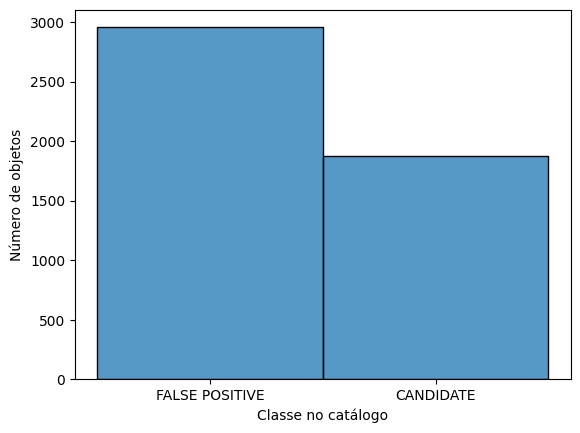

In [4]:
eixo = sns.histplot(data=df_treino, x=TARGET[0], color=sns.color_palette()[0])
eixo.set(xlabel='Classe no catálogo', ylabel='Número de objetos')
plt.show()

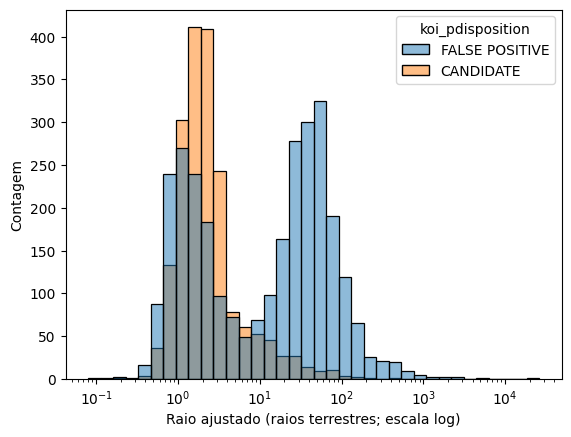

In [5]:
eixo = sns.histplot(data=df_treino, x='koi_prad', hue=TARGET[0], log_scale=True)
eixo.set(xlabel='Raio ajustado (raios terrestres; escala log)', ylabel='Contagem')
plt.show()

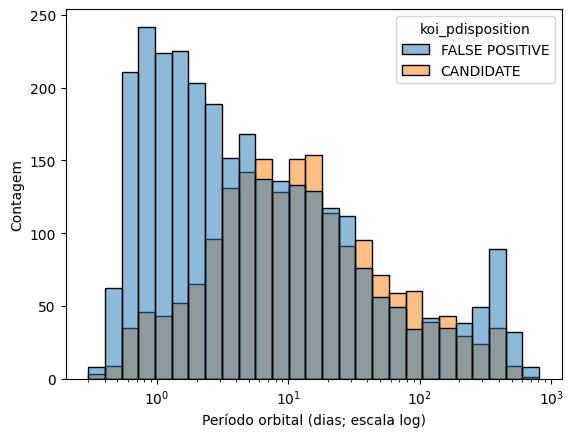

In [6]:
eixo = sns.histplot(data=df_treino, x='koi_period', hue=TARGET[0], log_scale=True)
eixo.set(xlabel='Período orbital (dias; escala log)', ylabel='Contagem')
plt.show()

As escalas diferentes justificam padronizar os atributos na logística e no k-NN. Árvores não exigem essa transformação para as divisões usadas aqui. Algumas medidas compartilham informação, como profundidade e razão dos raios. Isso motiva estudar PCA, sem presumir que a redução necessariamente aumente o F1.

## 5. Validação cruzada e baseline

A validação cruzada `cross_val_score` com `cv=NUM_FOLDS` e o estabelecimento do baseline funcionam como o primeiro parâmetro de avaliação adotando um classificador base ingênuo (`DummyClassifier`). O código avalia o F1 macro desse modelo, que sempre tenta prever a classe globalmente mais frequente ao longo de cinco partições, para definir o patamar minimo a ser superado pelos outros modelos. O Optuna seleciona hiperparâmetros por essas médias; elas não são uma avaliação independente depois da busca. Scaler e PCA ficam dentro dos pipelines e são ajustados apenas no treino de cada fold.
A métrica é **F1 macro**: calcula-se o F1 de cada classe e a média simples, dando peso igual às classes. Para uma classe, $F1=2PR/(P+R)$, com precisão $P$ e recall $R$. O baseline sempre prevê a classe mais frequente.

In [7]:
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

NUM_FOLDS = 5
NUM_TENTATIVAS = 100
optuna.logging.set_verbosity(optuna.logging.WARNING)

modelo_baseline = DummyClassifier(strategy='most_frequent')
metricas = cross_val_score(
    modelo_baseline, X_treino, y_treino,
    cv=NUM_FOLDS, scoring='f1_macro', n_jobs=4
)
f1_cv_baseline = metricas.mean()
print('F1 CV do baseline:', f1_cv_baseline)

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


F1 CV do baseline: 0.3795582795541931


## 6. Regressão logística

O bloco da regressão logística estrutura a construção desse algoritmo aliada ao framework de experimentação Optuna para descobrir os melhores valores da força de regularização matemática e do rebalanceamento de peso das classes. Para garantir uma execução estável onde medidas com valores absolutos muito grandes não dominem a conta da regressão, o algoritmo é empacotado em um pipeline encadeado que sempre realiza a padronização estatística do conjunto de treinamento a cada tentativa.

In [8]:
from sklearn.linear_model import LogisticRegression


def cria_instancia_modelo(trial):
    parametros = {
        'C': trial.suggest_float('C', 0.0001, 1000, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        'max_iter': 4000
    }
    modelo = make_pipeline(StandardScaler(), LogisticRegression(**parametros))
    return modelo


def funcao_objetivo(trial):
    modelo = cria_instancia_modelo(trial)
    metricas = cross_val_score(
        modelo, X_treino, y_treino,
        cv=NUM_FOLDS, scoring='f1_macro', n_jobs=4
    )
    return metricas.mean()

estudo_logistica = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=SEMENTE_ALEATORIA)
)
estudo_logistica.optimize(funcao_objetivo, n_trials=NUM_TENTATIVAS)
modelo_logistica = cria_instancia_modelo(estudo_logistica.best_trial)
print('Melhor F1 CV:', estudo_logistica.best_value)

Melhor F1 CV: 0.817750185595138


## 7. k-NN com PCA

O algoritmo k-NN atua em conjunto com a ferramenta de redução de componentes principais PCA em uma estrutura única preenchida e escalonada. A busca otimizada seleciona dinamicamente a quantidade de componentes numéricos sintéticos ideais para resumir a tabela, ao mesmo tempo que averigua o comportamento do sistema ao alterar simultaneamente a métrica do grau de distância vizinha, o cálculo de potência e o modelo de votação estatística.

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA


def cria_instancia_modelo(trial):
    parametros = {
        'n_neighbors': trial.suggest_int('n_neighbors', 3, 61),
        'weights': trial.suggest_categorical('weights', ['uniform', 'distance']),
        'p': trial.suggest_float('p', 1, 2)
    }
    componentes = trial.suggest_int('componentes', 2, 24)
    modelo = make_pipeline(
        StandardScaler(),
        PCA(n_components=componentes),
        KNeighborsClassifier(**parametros)
    )
    return modelo


def funcao_objetivo(trial):
    modelo = cria_instancia_modelo(trial)
    metricas = cross_val_score(
        modelo, X_treino, y_treino,
        cv=NUM_FOLDS, scoring='f1_macro', n_jobs=4
    )
    return metricas.mean()

estudo_knn = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=SEMENTE_ALEATORIA)
)
estudo_knn.optimize(funcao_objetivo, n_trials=NUM_TENTATIVAS)
modelo_knn = cria_instancia_modelo(estudo_knn.best_trial)
print('Melhor F1 CV:', estudo_knn.best_value)

Melhor F1 CV: 0.8048556827965971


## 8. Árvore de decisão

O estudo com árvore de decisão trabalha com um modelo mais interpretativo da informação que dispensa a transformação escalonada de valores. A investigação algorítmica experimenta critérios estritos de particionamento interno do aprendizado em até 100 rodadas de ajuste, impondo limites estruturais rígidos à profundidade total do desenho e ao volume necessário de amostras para o corte por ramos, a fim de bloquear especializações extremas, que o modelo fique bitolado.

In [10]:
from sklearn.tree import DecisionTreeClassifier


def cria_instancia_modelo(trial):
    parametros = {
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'max_depth': trial.suggest_int('max_depth', 2, 24),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 30),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 25),
        'max_features': trial.suggest_float('max_features', 0.4, 1),
        'random_state': SEMENTE_ALEATORIA
    }
    modelo = DecisionTreeClassifier(**parametros)
    return modelo


def funcao_objetivo(trial):
    modelo = cria_instancia_modelo(trial)
    metricas = cross_val_score(
        modelo, X_treino, y_treino,
        cv=NUM_FOLDS, scoring='f1_macro', n_jobs=4
    )
    return metricas.mean()

estudo_arvore = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=SEMENTE_ALEATORIA)
)
estudo_arvore.optimize(funcao_objetivo, n_trials=NUM_TENTATIVAS)
modelo_arvore = cria_instancia_modelo(estudo_arvore.best_trial)
print('Melhor F1 CV:', estudo_arvore.best_value)

Melhor F1 CV: 0.8241714720339383


## 9. Random Forest

A análise baseada em Random Forest alavanca o desempenho das decisões em árvore agrupando uma floresta densa de instâncias aleatorizadas cujas votações são independentes. A busca computacional alterna a quantidade bruta de estimadores atuantes entre 80 e 200 cópias, refinando ao mesmo tempo a permissão máxima para o avanço da profundidade individual e a fração parcial de sorteio das colunas em cada ramificação do aprendizado.

In [11]:
from sklearn.ensemble import RandomForestClassifier


def cria_instancia_modelo(trial):
    parametros = {
        'n_estimators': trial.suggest_int('n_estimators', 80, 200, step=40),
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'max_depth': trial.suggest_int('max_depth', 4, 24),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 15),
        'max_features': trial.suggest_float('max_features', 0.3, 1),
        'bootstrap': True,
        'random_state': SEMENTE_ALEATORIA
    }
    modelo = RandomForestClassifier(**parametros)
    return modelo


def funcao_objetivo(trial):
    modelo = cria_instancia_modelo(trial)
    metricas = cross_val_score(
        modelo, X_treino, y_treino,
        cv=NUM_FOLDS, scoring='f1_macro', n_jobs=4
    )
    return metricas.mean()

estudo_floresta = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=SEMENTE_ALEATORIA)
)
estudo_floresta.optimize(funcao_objetivo, n_trials=NUM_TENTATIVAS)
modelo_floresta = cria_instancia_modelo(estudo_floresta.best_trial)
print('Melhor F1 CV:', estudo_floresta.best_value)

Melhor F1 CV: 0.8533816255211301


## 10. HistGradientBoosting

O boosting acrescenta árvores sequencialmente para reduzir a função de perda; a versão usada organiza os valores em histogramas. Foi testada a taxa de aprendizado de 0,02 a 0,2, 80 a 240 etapas em passos de 40, 7 a 47 folhas, mínimo de 10 a 60 exemplos por folha e regularização L2 de 0,00001 a 10. Essas faixas exploram capacidades diferentes com custo viável. A varredura testa intensivamente modificadores como a taxa restritiva de velocidade no aprendizado, o valor de penalidade regularizada por L2, a variação limite das folhas nodais e o patamar ininterrupto da quantidade de repetições sequenciais sem gatilhos para que o procedimento encerre antecipadamente 

In [12]:
from sklearn.ensemble import HistGradientBoostingClassifier


def cria_instancia_modelo(trial):
    parametros = {
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
        'max_iter': trial.suggest_int('max_iter', 80, 240, step=40),
        'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 7, 47),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 10, 60),
        'l2_regularization': trial.suggest_float('l2_regularization', 0.00001, 10, log=True),
        'early_stopping': False,
        'random_state': SEMENTE_ALEATORIA
    }
    modelo = HistGradientBoostingClassifier(**parametros)
    return modelo


def funcao_objetivo(trial):
    modelo = cria_instancia_modelo(trial)
    metricas = cross_val_score(
        modelo, X_treino, y_treino,
        cv=NUM_FOLDS, scoring='f1_macro', n_jobs=4
    )
    return metricas.mean()

estudo_boosting = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=SEMENTE_ALEATORIA)
)
estudo_boosting.optimize(funcao_objetivo, n_trials=NUM_TENTATIVAS)
modelo_boosting = cria_instancia_modelo(estudo_boosting.best_trial)
print('Melhor F1 CV:', estudo_boosting.best_value)

Melhor F1 CV: 0.8632784924632079


## 11. Comparar pela validação cruzada

A etapa de comparação computada reúne o histórico das maiores pontuações consolidadas pelo F1 macro oriundas das otimizações finalizadas nos processos anteriores e escolhe analiticamente a ferramenta de maior sucesso. O trecho também invoca um plot de pilar que mostra visualmente o ganho de eficiência técnica entre as seis lógicas avaliadas na etapa restrita aos ciclos de divisão.

Selecionado pela CV: Boosting


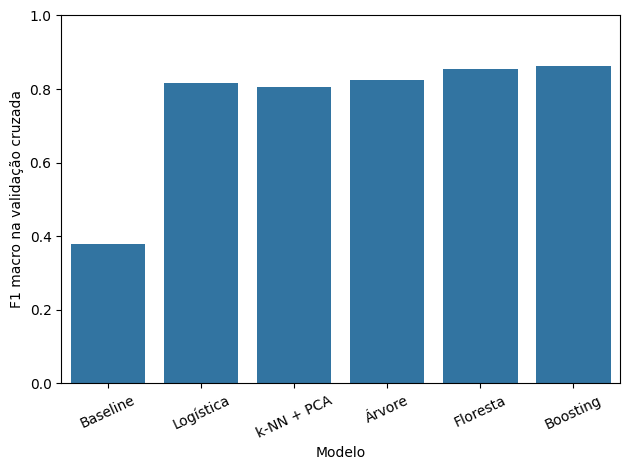

In [13]:
nomes = ['Baseline', 'Logística', 'k-NN + PCA', 'Árvore', 'Floresta', 'Boosting']
modelos = [modelo_baseline, modelo_logistica, modelo_knn,
           modelo_arvore, modelo_floresta, modelo_boosting]
metricas_cv = [f1_cv_baseline, estudo_logistica.best_value, estudo_knn.best_value,
              estudo_arvore.best_value, estudo_floresta.best_value, estudo_boosting.best_value]

melhor_indice = metricas_cv.index(max(metricas_cv))
melhor_modelo = modelos[melhor_indice]
print('Selecionado pela CV:', nomes[melhor_indice])

eixo = sns.barplot(x=nomes, y=metricas_cv, color=sns.color_palette()[0])
eixo.set(xlabel='Modelo', ylabel='F1 macro na validação cruzada', ylim=(0, 1))
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 12. Ajustar e avaliar

O roteiro de ajustar e avaliar extrai todos os classificadores configurados pela otimização e processa um ensaio alimentando-os uma última vez com a base unificada integral de treinamento. A performance decisiva e prática do método aumenta quando as métricas testam a matriz de validação histórica, momento seguido de imediato pela construção do mapa visual da matriz de confusão.

In [14]:
for i in range(len(modelos)):
    modelo = modelos[i]
    modelo.fit(X_treino, y_treino)

    previsao_treino = modelo.predict(X_treino)
    previsao_teste = modelo.predict(X_teste)

    f1_treino = f1_score(y_treino, previsao_treino, average='macro')
    f1_teste = f1_score(y_teste, previsao_teste, average='macro')

    print(nomes[i], '| F1 treino:', round(f1_treino, 4),
          '| F1 CV:', round(metricas_cv[i], 4), '| F1 teste:', round(f1_teste, 4))

Baseline | F1 treino: 0.3796 | F1 CV: 0.3796 | F1 teste: 0.3797
Logística | F1 treino: 0.8199 | F1 CV: 0.8178 | F1 teste: 0.7952


k-NN + PCA | F1 treino: 1.0 | F1 CV: 0.8049 | F1 teste: 0.7973
Árvore | F1 treino: 0.8417 | F1 CV: 0.8242 | F1 teste: 0.8022


Floresta | F1 treino: 0.984 | F1 CV: 0.8534 | F1 teste: 0.8316


Boosting | F1 treino: 1.0 | F1 CV: 0.8633 | F1 teste: 0.8459


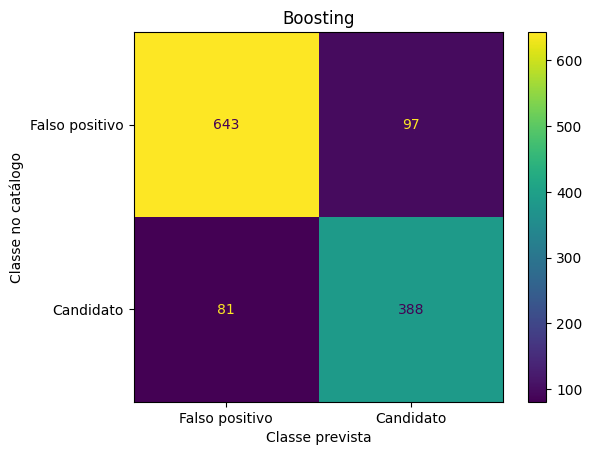

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

previsao = melhor_modelo.predict(X_teste)
ConfusionMatrixDisplay.from_predictions(y_teste, previsao, display_labels=['Falso positivo', 'Candidato'])
plt.xlabel('Classe prevista')
plt.ylabel('Classe no catálogo')
plt.title(nomes[melhor_indice])
plt.show()

## 13. Permutation importance

A aplicação do cálculo de importância por permutação interroga de forma passiva as características mais determinates para o acerto sem demandar processamentos. O sistema aleatoriza individualmente vinte iterações de falhas sobre o catálogo de verificação até imprimir graficamente o eixo de pontuação da relevância do F1 impactado na previsão horizontal.

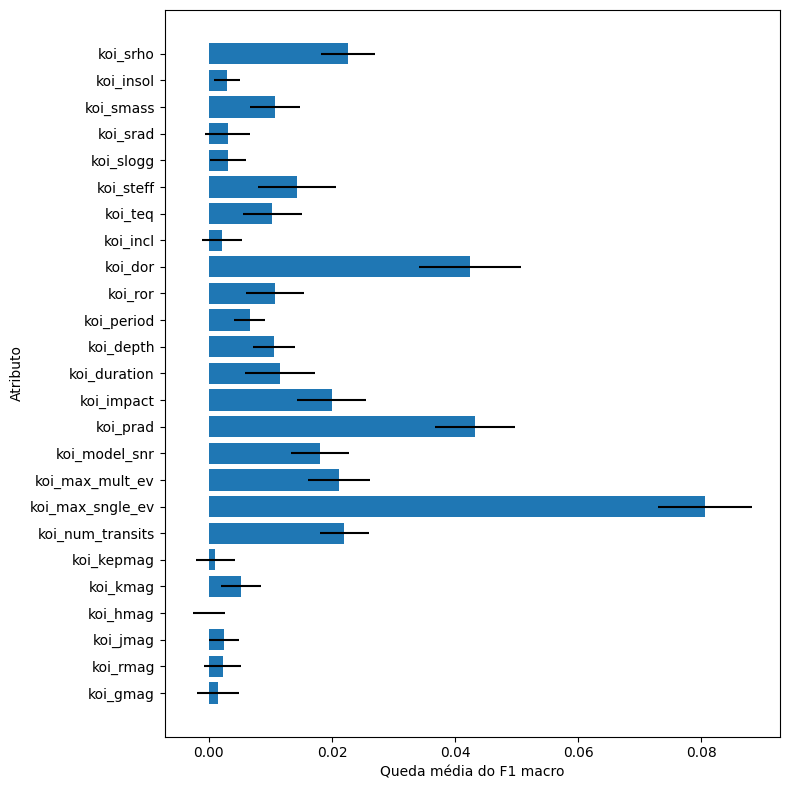

In [16]:
from sklearn.inspection import permutation_importance

importancia = permutation_importance(
    melhor_modelo, X_teste, y_teste,
    scoring='f1_macro', n_repeats=20, random_state=SEMENTE_ALEATORIA
)

plt.figure(figsize=(8, 8))
plt.barh(ATRIBUTOS, importancia.importances_mean, xerr=importancia.importances_std)
plt.xlabel('Queda média do F1 macro')
plt.ylabel('Atributo')
plt.tight_layout()
plt.show()

## 14. Discussão dos resultados

Após remover dados ausentes, restaram 6.041 exemplos: 3.696 falsos positivos e 2.345 candidatos. O treino contém 2.956 falsos positivos e 1.876 candidatos; o teste, 740 e 469. A remoção excluiu 99 falsos positivos e 8 candidatos, logo não foi proporcional entre as classes.

Os histogramas mostram distribuições diferentes de raio ajustado e período, com sobreposição. No treino, o raio mediano é de 2,01 raios terrestres nos candidatos e 18,22 nos falsos positivos; o período mediano é 10,75 e 3,82 dias, respectivamente. Essas diferenças ajudam a formular a tarefa, mas não oferecem uma fronteira suficiente para confirmar planetas. As estatísticas também mostram escalas muito diferentes, justificando os scalers nos pipelines apropriados.

**Baseline:** F1 de treino 0.3796; F1 médio de CV 0.3796; F1 de teste histórico 0.3797.

**Logística:** F1 de treino 0.8199; F1 médio de CV 0.8178; F1 de teste histórico 0.7952.

**k-NN + PCA:** F1 de treino 1.0000; F1 médio de CV 0.8049; F1 de teste histórico 0.7973.

**Árvore:** F1 de treino 0.8417; F1 médio de CV 0.8242; F1 de teste histórico 0.8022.

**Floresta:** F1 de treino 0.9840; F1 médio de CV 0.8534; F1 de teste histórico 0.8316.

**Boosting:** F1 de treino 1.0000; F1 médio de CV 0.8633; F1 de teste histórico 0.8459.

O selecionado pela validação cruzada foi **Boosting**, com F1 médio de **0.8633**. O vencedor da CV também apresentou o maior F1 no teste nesta execução. A decisão, porém, já estava tomada antes de consultar o teste.

O baseline sempre prevê a classe mais frequente, deixando de recuperar candidatos. Os modelos aprendidos superaram essa referência nesta execução. O F1 de treino do vencedor foi 1.0000, enquanto no teste foi 0.8459; a diferença mostra por que ajustar bem as observações conhecidas não garante igual desempenho fora do ajuste. As médias de CV foram usadas para selecionar hiperparâmetros, e diferenças pequenas não demonstram superioridade universal.

Na matriz de confusão, 643 falsos positivos do catálogo foram reconhecidos corretamente e 97 foram previstos como candidatos. Entre os candidatos, 388 foram recuperados e 81 foram rejeitados. Esses erros se referem aos rótulos históricos do catálogo.

O k-NN selecionou **22 componentes** dentre os 25 atributos originais. O PCA foi aprendido dentro de cada fold e seu número de componentes foi controlado pelo Optuna. Como não isolamos o mesmo k-NN com e sem PCA, não atribuímos uma melhora exclusivamente à redução.

As três maiores quedas médias de F1 por permutação foram `koi_max_sngle_ev` (0.0806), `koi_prad` (0.0433), `koi_dor` (0.0425). O classificador depende dessas informações neste conjunto. Correlações podem fazer atributos substituírem informação uns dos outros; importância pequena não significa irrelevância física, e importância alta não demonstra causalidade. Não alteramos atributos ou hiperparâmetros depois dessa análise.

Foram executadas e conferidas 100 configurações distintas por algoritmo, 500 no total, cada uma avaliada em cinco folds. O código executou em ordem sem erros de execução. Surgiu apenas um aviso não bloqueante sobre a barra de progresso (IProgress indisponível neste ambiente). O teste permanece histórico; não é uma avaliação externa inédita.

## 15. Referências


1. https://pt.wikipedia.org/wiki/Exoplaneta

2. https://data.nasa.gov/dataset/kepler-objects-of-interest-koi

3. https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=cumulative

## Descrição do uso de IA neste trabalho

Durante o desenvolvimento deste projeto, ferramentas de Inteligência Artificial foram utilizadas como um apoio prático e complementar, ajudando a agilizar a montagem dos códigos, a tirar dúvidas sobre o funcionamento das bibliotecas e a revisar os textos explicativos do caderno, também foi usada para encontrar o datase a na contextualização do problema científico.
Link: https://chatgpt.com/share/6af42d76-9d78-83e9-9aa6-a3c556bc0604

## Conclusões e principais aprendizados

O **HistGradientBoosting** foi escolhido por F1 médio de CV de **0.8633**, com F1 de **0.8459** no teste histórico. Os resultados mostram capacidade de reproduzir parte da triagem do catálogo neste recorte, sem confirmar novos planetas.

foram comparados cinco algoritmos além do baseline, com 100 configurações distintas por algoritmo. A CV foi mantida dentro do treino, scaler e PCA foram usados dentro dos pipelines e o vencedor foi interpretado por permutação. O k-NN utilizou 22 componentes escolhidos pelo Optuna.

Os principais aprendizados são comparar com uma referência simples, separar seleção e avaliação, aprender transformações dentro dos folds, observar sobreajuste e interpretar os resultados respeitando as limitações dos rótulos e dos dados.